<a href="https://colab.research.google.com/github/alwinbshaji/Data-Science/blob/main/binaryclassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Binary classification - Heart Disease Dataset

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
mydf = pd.read_csv('/content/drive/MyDrive/faith fahhhhh/heart.csv')
mydf.head(3)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1


In [42]:
mydf.shape

(303, 14)

EDA

In [43]:
print(mydf.shape)
print(mydf.count())
print(mydf.describe())
print(mydf.info())

(303, 14)
age         303
sex         303
cp          303
trestbps    303
chol        303
fbs         303
restecg     303
thalach     303
exang       303
oldpeak     303
slope       303
ca          303
thal        303
target      303
dtype: int64
              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.366337    0.683168    0.966997  131.623762  246.264026    0.148515   
std      9.082101    0.466011    1.032052   17.538143   51.830751    0.356198   
min     29.000000    0.000000    0.000000   94.000000  126.000000    0.000000   
25%     47.500000    0.000000    0.000000  120.000000  211.000000    0.000000   
50%     55.000000    1.000000    1.000000  130.000000  240.000000    0.000000   
75%     61.000000    1.000000    2.000000  140.000000  274.500000    0.000000   
max     77.000000    1.000000    3.000000  200.000000  564.000000    1.000000   

          restecg     t

In [44]:
print(mydf.isna().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


<Axes: xlabel='target', ylabel='count'>

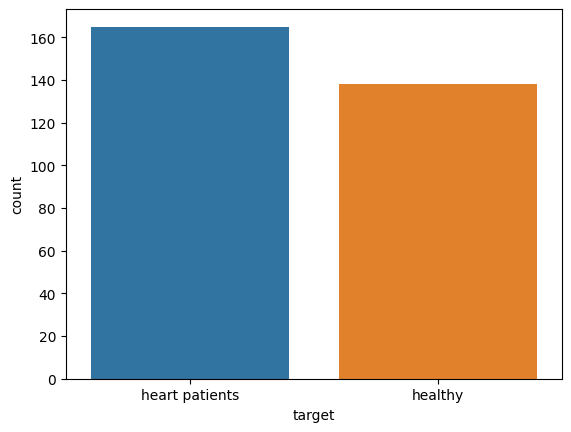

In [45]:
#to keep the original data createa a coy of the current data frame
mydf_cpy = mydf.copy()

#createa a barchart to compare the no of healty vs patients
#createa a mapping of the target collumn,= 0 for healthy and 1 for patients
mydf_cpy.target = mydf_cpy.target.map({0:'healthy',1:'heart patients'}
)
#createa a count plaot using sns
sns.countplot(x='target',data=mydf_cpy,hue=mydf_cpy.target)

<Axes: xlabel='sex', ylabel='count'>

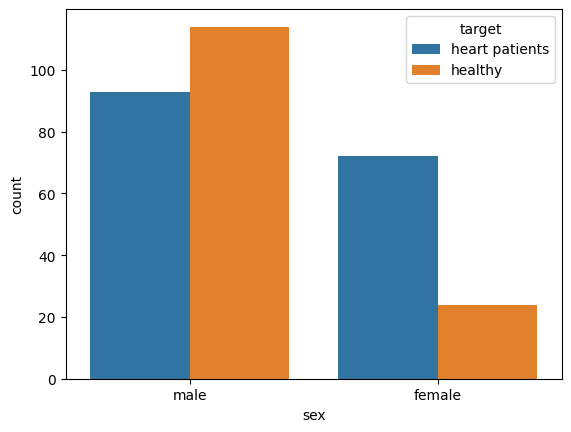

In [46]:
#create a barcahrt to compare the no of healty vs patients vs gender
#createa a barchart to compare the no of healty vs patients
#createa a mapping of the target collumn,= 0 for healthy and 1 for patients
mydf_cpy.sex = mydf_cpy.sex.map({0:'female',1:'male'}
)
#createa a count plaot using sns
sns.countplot(x='sex',data=mydf_cpy,hue=mydf_cpy.target)

In [47]:
#define the model
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [48]:
#using sequential model
model = keras.Sequential()
model.add(layers.Dense(11,input_dim=13,activation='relu'))
model.add(layers.Dense(8,activation='relu'))
model.add(layers.Dense(4,activation='relu'))
model.add(layers.Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [49]:
#compile the model
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [50]:
#split the dataset inte input x and input y
x= mydf.drop('target',axis=1)
y= mydf['target']

In [51]:
#fit and train the modely
history = model.fit(x,y,validation_split=0.22,epochs=300)

Epoch 1/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.3008 - loss: 24.6167 - val_accuracy: 1.0000 - val_loss: 4.0160e-08
Epoch 2/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3008 - loss: 17.9698 - val_accuracy: 1.0000 - val_loss: 2.9588e-06
Epoch 3/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3008 - loss: 11.8538 - val_accuracy: 1.0000 - val_loss: 6.3551e-05
Epoch 4/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3008 - loss: 7.6994 - val_accuracy: 1.0000 - val_loss: 7.8048e-04
Epoch 5/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3008 - loss: 5.2015 - val_accuracy: 1.0000 - val_loss: 0.0048
Epoch 6/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3263 - loss: 3.5978 - val_accuracy: 1.0000 - val_loss: 0.0219
Epoch 7/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3602 - loss: 2.4646 - val_accuracy: 0.9851 - val_loss: 0.0920
Epoch 8/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4703 - loss: 1.7004 - val_accuracy:

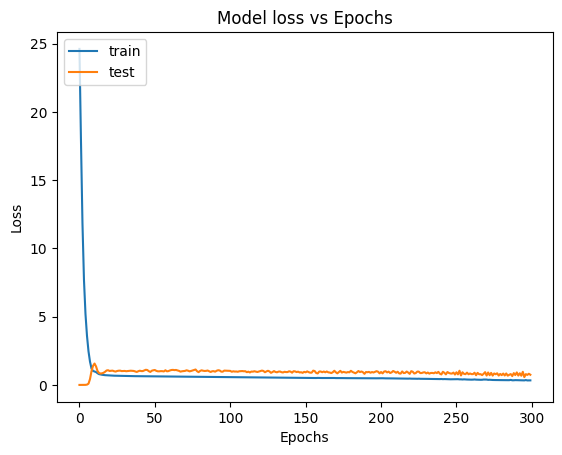

In [52]:
# we will plot a graph from the metric history variable
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss vs Epochs')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['train','test'],loc='upper left')
plt.show()

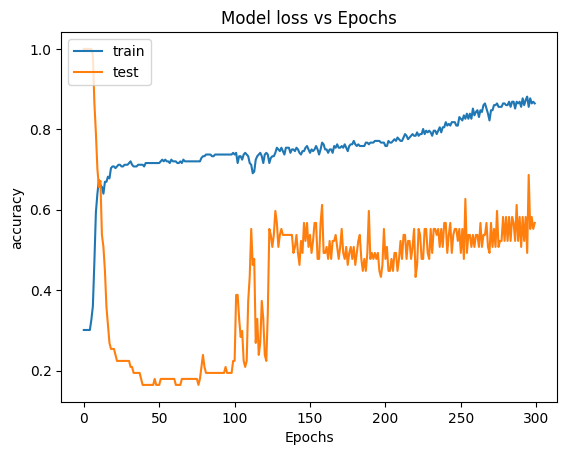

In [53]:
# we will plot a graph from the metric history variable
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model loss vs Epochs')
plt.ylabel('accuracy')
plt.xlabel('Epochs')
plt.legend(['train','test'],loc='upper left')
plt.show()

In [56]:
# get a set of 13 sample input values to predict the output
input_to_predict = [45,1,3,120,250,0,1,132,0,1.2,1,0,3]
# convert the input into a float numpy array
input_to_predict = np.array([input_to_predict],
                            dtype=np.float64)
# predict using predict() fn
prediction = model.predict(input_to_predict)
# print the prediction
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
[[0.7693498]]


In [57]:
probability = prediction[0][0]
if probability >=0.5:
  print("The predicted target is 1 the person has disease")
else:
  print("the predicted target is 0 the person is healthy")

The predicted target is 1 the person has disease


In [58]:
#evaluate our trained model to egt the accuracy sand loss
eval_history = model.evaluate(x,y)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8020 - loss: 0.4188 
